# KelpAdam – UAS Pembelajaran Mesin
## Notebook B – Regresi Prediksi IPK dari Survei Preferensi Belajar (VARK)

**Tujuan:** memprediksi IPK (angka kontinu 0–4) dari jawaban 16 skenario VARK, lalu membandingkan **Linear Regression** dan **Random Forest Regressor** secara adil, dengan baseline sebagai patokan.

| Komponen | Isi |
|---|---|
| Sumber data | `dataset/processed_UTS/KelpAdam_survey_prepared.csv` (hasil notebook UTS, 192 responden) |
| Framework | VARK: 64 indikator 0/1 dari 16 skenario |
| Target y | `IPK` (kolom DL pada data dosen), numerik |
| Pembagian data | train 80% : test 20%, `random_state = 42` |
| Model | Baseline rerata, Linear Regression, Random Forest Regressor |
| Metrik | MAE, RMSE, R² pada test set |

**Alur notebook:** B0 Setup → B1 Data & definisi X/y → B2 Preprocessing & cleaning → B3 EDA → B4 Split & pipeline → B5 Training & pemilihan model → B6 Evaluasi test → B7 Simpan model.

**Batas interpretasi:** model ini hanya memeriksa apakah jawaban survei membantu memperkirakan IPK pada data yang tersedia. Hasilnya bukan bukti bahwa preferensi belajar *menyebabkan* IPK. Karena urutan waktu pengisian survei dan IPK tidak diketahui, model juga tidak diklaim sebagai prediksi dini.

---
# B0 – Setup

Semua library, konstanta, dan path didefinisikan di satu sel supaya notebook bisa dijalankan ulang dari awal (*Restart & Run All*).
- `SEED = 42` dan `TEST_SIZE = 0.2` sesuai spesifikasi UAS dan dipakai di seluruh notebook.
- Path dibuat **relatif terhadap folder proyek**, sama seperti notebook UTS kemarin, sehingga notebook berjalan di laptop anggota mana pun tanpa mengubah kode.
- Versi library dicetak sebagai bukti reproduksibilitas. Versi scikit-learn penting karena model `.joblib` hanya aman dimuat dengan versi yang sama.

In [1]:
import json
import platform
from pathlib import Path

import joblib
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import display
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (GridSearchCV, KFold, cross_validate,
                                     permutation_test_score, train_test_split)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# --- Konstanta eksperimen (sesuai spesifikasi UAS) ---
SEED = 42          # random_state wajib
TEST_SIZE = 0.2    # train : test = 80 : 20

# --- Path relatif: notebook berada di <folder proyek>/notebook/ ---
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebook" else Path.cwd()
DATA_FILE = PROJECT_DIR / "dataset" / "processed_UTS" / "KelpAdam_survey_prepared.csv"
DATA_OUT  = PROJECT_DIR / "dataset" / "processed_UAS"     # Dataset_regresi.csv
MODEL_DIR = PROJECT_DIR / "models"                        # Model_regresi.joblib
OUT_DIR   = PROJECT_DIR / "figures_and_outputs"           # grafik & tabel (prefix B)
for folder in (DATA_OUT, MODEL_DIR, OUT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

# --- Tampilan tabel & grafik ---
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})
BIRU, ORANYE, ABU = "#2b6cb0", "#dd6b20", "#a0aec0"


def simpan_fig(fig, nama):
    """Simpan grafik ke figures_and_outputs/<nama>.png lalu tampilkan."""
    path = OUT_DIR / f"{nama}.png"
    fig.savefig(path, bbox_inches="tight", dpi=150)
    plt.show()
    print("Disimpan:", path.relative_to(PROJECT_DIR))


def simpan_tabel(tabel, nama):
    """Simpan tabel ke figures_and_outputs/<nama>.csv agar angka laporan bisa ditelusuri."""
    path = OUT_DIR / f"{nama}.csv"
    tabel.to_csv(path)
    print("Disimpan:", path.relative_to(PROJECT_DIR))


print("Folder proyek :", PROJECT_DIR)
print("File data     :", DATA_FILE.relative_to(PROJECT_DIR), "| ada?", DATA_FILE.exists())
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | scipy {scipy.__version__} | "
      f"matplotlib {matplotlib.__version__} | joblib {joblib.__version__}")

Folder proyek : d:\Kuliah\Semester 5\Machine Learning\KelpAdam_UAS_MachineLearning
File data     : dataset\processed_UTS\KelpAdam_survey_prepared.csv | ada? True
Python 3.12.10 | pandas 3.1.1 | numpy 2.5.5 | scikit-learn 1.9.1 | scipy 1.18.1 | matplotlib 3.11.2 | joblib 1.6.0


---
# B1 – Memuat data & mendefinisikan X dan y

## B1.1 Memuat dataset hasil UTS
Panduan UAS menyatakan bahwa *UAS menggunakan dataset yang dihasilkan pada UTS*. Dataset ini sudah melalui cleaning C1–C10 di notebook UTS (194 → 192 baris) dan berisi item mentah, skor, label, serta 64 indikator VARK. File UTS hanya **dibaca**, tidak diubah.

In [2]:
df = pd.read_csv(DATA_FILE)
print("Ukuran dataset:", df.shape)

# Memastikan ukuran harus sama dengan yang diharapkan
assert df.shape == (192, 216), "Ukuran berbeda dari output UTS; periksa file di dataset/processed_UTS/"
assert df["ID"].is_unique, "ID tidak unik"

# Menampilkan contoh 5 baris pertama dataset
display(df[["ID", "IPK", "VARK_Q01", "VARK_Q01_V", "VARK_Q01_A", "VARK_Q01_R", "VARK_Q01_K"]].head())

Ukuran dataset: (192, 216)


,ID,IPK,VARK_Q01,VARK_Q01_V,VARK_Q01_A,VARK_Q01_R,VARK_Q01_K
0,1,3.78,"melihat diagram, bagan, peta konsep, atau ilus...",1,1,0,0
1,2,3.83,"melihat diagram, bagan, peta konsep, atau ilus...",1,0,0,1
2,3,3.77,"melihat diagram, bagan, peta konsep, atau ilus...",1,0,0,1
3,4,1.97,"mencoba contoh, simulasi, praktik, atau meliha...",0,0,1,1
4,5,3.54,mendengar penjelasan dan dapat berdiskusi atau...,0,1,0,0


## B1.2 Alasan memilih framework VARK

| Alasan | Bukti |
|---|---|
| Semua framework sama-sama lemah hubungannya dengan IPK, jadi tidak ada framework yang jelas lebih unggul untuk regresi | EDA UTS (E6 lanjutan): korelasi setiap item dengan IPK paling besar \|ρ\| 0,20–0,23 di keempat framework, dan tidak ada yang signifikan setelah koreksi FDR |
| Tidak terdampak responden berpola seragam (*straightliner*) | Pola seragam ditemukan pada 88 item skala 1–5 (UTS C9); VARK berformat pilihan, dan jawaban VARK responden tersebut tetap bervariasi (dicek di B2.5) |
| Fitur sudah siap dan terverifikasi | 64 indikator 0/1 dibuat dan diverifikasi di UTS (S1, S5) |
| Konsisten dengan Proyek A (klasifikasi) | Satu skema input untuk kedua tab Streamlit dan satu fungsi encoding, sehingga risiko input aplikasi berbeda dengan training lebih kecil |

## B1.3 Definisi fitur X dan target y

- **X** = 64 kolom `VARK_Qxx_M`: `xx` = nomor skenario 01–16, `M` = modalitas V (Visual, opsi A), A (Aural, opsi B), R (Read/Write, opsi C), K (Kinesthetic, opsi D), sesuai Lampiran panduan. Nilai **1 = opsi dipilih**, **0 = tidak dipilih**. Satu skenario boleh punya lebih dari satu angka 1 karena pertanyaannya pilihan jamak.
- **y** = `IPK`, angka kontinu skala 0–4. IPK tidak diubah menjadi kategori karena tugas ini regresi.
- **Urutan kolom X dikunci** di `FEATURE_COLS`. Urutan yang sama wajib dipakai aplikasi Streamlit saat membuat input untuk model.

In [3]:
MODALITAS = ["V", "A", "R", "K"]   # urutan opsi A, B, C, D pada instrumen
FEATURE_COLS = [f"VARK_Q{q:02d}_{m}" for q in range(1, 17) for m in MODALITAS]
TARGET = "IPK"

assert len(FEATURE_COLS) == 64
kolom_hilang = [c for c in FEATURE_COLS if c not in df.columns]
assert not kolom_hilang, f"Kolom fitur tidak ditemukan: {kolom_hilang}"

print(f"Jumlah fitur X : {len(FEATURE_COLS)} (16 skenario x 4 modalitas)")
print("8 kolom pertama:", FEATURE_COLS[:8])
print("Target y       :", TARGET)

Jumlah fitur X : 64 (16 skenario x 4 modalitas)
8 kolom pertama: ['VARK_Q01_V', 'VARK_Q01_A', 'VARK_Q01_R', 'VARK_Q01_K', 'VARK_Q02_V', 'VARK_Q02_A', 'VARK_Q02_R', 'VARK_Q02_K']
Target y       : IPK


## B1.4 Kolom yang tidak dipakai sebagai fitur
Spesifikasi dan Panduan Regresi melarang memasukkan ID, IPS, label gaya belajar, skor ringkasan, dan item framework lain ke X. Sel berikut mengelompokkan **seluruh 216 kolom** beserta alasannya, lalu memastikan dengan `assert` bahwa X hanya berisi 64 indikator VARK.

In [4]:
SKOR_VARK = ["VARK_V", "VARK_A", "VARK_R", "VARK_K", "VARK_total"]

def peran_kolom(kolom):
    """Kembalikan (kelompok, alasan) untuk setiap kolom dataset UTS."""
    if kolom == "ID":
        return "Identifier", "Nomor urut; hanya untuk melacak baris"
    if kolom == TARGET:
        return "Target y", "IPK numerik = target regresi"
    if kolom in FEATURE_COLS:
        return "Fitur X", "Indikator VARK 0/1"
    if kolom.startswith("IPS_"):
        return "IPS per semester", "Dilarang; IPK dihitung dari IPS sehingga membocorkan target"
    if kolom in SKOR_VARK:
        return "Skor VARK", "Skor ringkasan gaya belajar tidak boleh jadi fitur tambahan"
    if kolom.endswith("_label"):
        return "Label gaya belajar", "Dilarang sebagai fitur regresi"
    if kolom.startswith("VARK_Q"):
        return "Teks jawaban VARK", "Sudah diwakili 64 indikator; teks disimpan untuk audit"
    if kolom.startswith(("HM_", "FS_", "KOLB_")):
        return "Framework lain (item & skor)", "X hanya dari satu framework"
    return "Variabel bantu UTS", "Konteks/kualitas data (angkatan, flag), bukan item survei"

peran = pd.DataFrame([(c, *peran_kolom(c)) for c in df.columns], columns=["kolom", "kelompok", "alasan"])
ringkas_peran = (peran.groupby(["kelompok", "alasan"], sort=False)
                 .agg(jumlah_kolom=("kolom", "size"), contoh=("kolom", lambda s: ", ".join(s[:3])))
                 .reset_index().set_index("kelompok"))
display(ringkas_peran)

# Pengaman anti-leakage
assert ringkas_peran["jumlah_kolom"].sum() == df.shape[1] == 216
assert peran.loc[peran["kelompok"] == "Fitur X", "kolom"].tolist() == FEATURE_COLS
dilarang = peran.loc[~peran["kelompok"].isin(["Fitur X"]), "kolom"]
assert not set(FEATURE_COLS) & set(dilarang), "Ada kolom terlarang di X"
print("OK: X hanya berisi 64 indikator VARK; ID, IPS, skor, label, dan framework lain tidak masuk X.")

,alasan,jumlah_kolom,contoh
kelompok,,,
Identifier,Nomor urut; hanya untuk melacak baris,1,ID
IPS per semester,Dilarang; IPK dihitung dari IPS sehingga membo...,9,"IPS_2022_S1, IPS_2022_S2, IPS_2023_S1"
Target y,IPK numerik = target regresi,1,IPK
Teks jawaban VARK,Sudah diwakili 64 indikator; teks disimpan unt...,16,"VARK_Q01, VARK_Q02, VARK_Q03"
Framework lain (item & skor),X hanya dari satu framework,110,"HM_ACT_01, HM_ACT_02, HM_ACT_03"
Skor VARK,Skor ringkasan gaya belajar tidak boleh jadi f...,5,"VARK_V, VARK_A, VARK_R"
Label gaya belajar,Dilarang sebagai fitur regresi,4,"VARK_label, FS_ACT_REF_label, HM_label"
Variabel bantu UTS,"Konteks/kualitas data (angkatan, flag), bukan ...",6,"angkatan_inferred, n_semester_ips, row_sd"
Fitur X,Indikator VARK 0/1,64,"VARK_Q01_V, VARK_Q01_A, VARK_Q01_R"


OK: X hanya berisi 64 indikator VARK; ID, IPS, skor, label, dan framework lain tidak masuk X.


## B1.5 Pemeriksaan awal target IPK
Cek tipe data, jumlah yang terisi, dan rentang. IPK yang sah berada di **0 hingga 4**.

In [5]:
print("Tipe data IPK:", df[TARGET].dtype)
ipk_terisi = df[TARGET].dropna()

ringkas_ipk = df[TARGET].describe().to_frame("IPK (192 baris)").T
ringkas_ipk.insert(1, "kosong", df[TARGET].isna().sum())
display(ringkas_ipk.round(2))

n_luar = int((~ipk_terisi.between(0, 4)).sum())
assert n_luar == 0, "Ada IPK di luar rentang 0-4"
print(f"IPK terisi: {len(ipk_terisi)} | kosong: {df[TARGET].isna().sum()} | di luar 0-4: {n_luar}")

Tipe data IPK: float64


,count,kosong,mean,std,min,25%,50%,75%,max
IPK (192 baris),173.0,19,3.36,0.45,0.87,3.19,3.42,3.67,4.0


IPK terisi: 173 | kosong: 19 | di luar 0-4: 0


**Ringkasan B1:**
- Dataset UTS terbaca utuh: **192 baris × 216 kolom**.
- **X = 64 indikator VARK** dengan urutan fix; **y = IPK** bertipe numerik (`float64`).
- Seluruh kolom lain (ID, 9 kolom IPS, 5 skor VARK, 4 label, 16 teks jawaban VARK, 88 item + 22 skor framework lain, 6 variabel bantu) dikeluarkan, dan dibuktikan dengan `assert`.
- IPK terisi **173**, kosong **19**, dan **tidak ada** nilai di luar 0–4. Penanganan 19 IPK kosong dibahas di B2.3.

---
# B2 – Preprocessing & justifikasi cleaning

Cleaning utama sudah dikerjakan di notebook UTS:

| Langkah UTS | Isi | Dampak |
|---|---|---|
| C2 | Hapus 2 respons kosong total (ID 11, 133) | 194 → 192 baris |
| C3, C4 | Validasi jawaban 1–5 dan opsi VARK terhadap daftar resmi | 0 nilai tidak valid |
| C6 | IPK = 0 pada mahasiswa tanpa IPS sebelumnya → kosong (NaN), karena berarti "belum ada nilai" | 4 sel |
| C7 | Validasi rentang IPS/IPK 0–4 dan konsistensi IPK vs rata-rata IPS | IPK rendah tetap dipertahankan |
| C9 | Flag pola jawaban seragam (*straightliner*) pada 88 item skala 1–5, tidak dihapus | 15 responden ditandai |

Di bagian ini data dicek ulang **khusus untuk regresi**, lalu ditentukan baris mana yang dipakai.

**Catatan:** pada tahap ini belum ada transformasi yang *belajar dari data* (scaling, imputasi, seleksi fitur). Semua transformasi seperti itu dilakukan di dalam pipeline **setelah** split (B4), supaya tidak terjadi *data leakage*.

## B2.0 Verifikasi pengodean VARK (Panduan Regresi 3B)
Panduan meminta jawaban VARK diubah menjadi fitur dengan langkah berikut: (1) pecah teks per titik koma dan abaikan token kosong akibat pemisah terakhir, (2) cocokkan setiap teks dengan opsi pada Lampiran panduan (A = Visual, B = Aural, C = Read/Write, D = Kinesthetic), (3) buat 4 indikator 0/1 per skenario sehingga total 64 fitur. Skenario kosong dicatat sebagai *missing* (bukan empat nol), dan teks yang tidak cocok diperiksa sebelum dikodekan.

64 indikator di dataset sudah dibuat di UTS (S1). Karena UAS dikerjakan di notebook terpisah, sel berikut **membuat ulang** pengodean dari 16 kolom teks jawaban dengan aturan panduan, lalu membuktikan bahwa hasilnya **identik** dengan 64 kolom UTS. Fungsi `encode_vark` ini juga yang akan dipakai aplikasi Streamlit, sehingga pengodean input aplikasi terbukti sama dengan pengodean saat training.

In [6]:
# Teks opsi resmi per skenario, urutan [A=Visual, B=Aural, C=Read/Write, D=Kinesthetic] (Lampiran Panduan)
VARK_OPSI = {
    1: ["melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.",
        "mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.",
        "membaca uraian tertulis, definisi, atau catatan yang terstruktur.",
        "mencoba contoh, simulasi, praktik, atau melihat penerapan nyata."],
    2: ["mengikuti gambar langkah demi langkah atau tangkapan layar.",
        "meminta seseorang menjelaskan langkah-langkahnya secara lisan.",
        "membaca petunjuk tertulis dan daftar langkah.",
        "langsung mencoba sambil memperbaiki kesalahan yang muncul."],
    3: ["membuat peta konsep, skema, warna, atau diagram.",
        "menjelaskan materi dengan suara keras atau berdiskusi dengan teman.",
        "menulis ulang ringkasan, membuat daftar, atau membaca catatan.",
        "berlatih soal, mencoba contoh, atau menghubungkan materi dengan pengalaman."],
    4: ["ada visualisasi yang menunjukkan hubungan antar konsep.",
        "penjelasan disampaikan dengan contoh verbal dan tanya jawab.",
        "tersedia teks atau rumusan tertulis yang dapat saya baca kembali.",
        "ada demonstrasi, studi kasus, atau aktivitas langsung."],
    5: ["melihat contoh hasil akhir atau struktur visual tugas.",
        "mendengarkan penjelasan dosen tentang apa yang harus dilakukan.",
        "membaca instruksi dan rubrik secara rinci.",
        "mencoba bagian awal tugas untuk memahami apa yang diminta."],
    6: ["melihat peta atau petunjuk arah visual.",
        "bertanya kepada orang lain dan mendengarkan arahannya.",
        "membaca nama jalan, papan petunjuk, atau instruksi tertulis.",
        "berjalan mencoba rute sambil menyesuaikan arah."],
    7: ["grafik, diagram, dan visualisasi pola.",
        "penjelasan lisan tentang makna hasil.",
        "tabel, uraian tertulis, dan penjelasan metodologis.",
        "contoh penerapan data pada kasus nyata."],
    8: ["menggambar skema atau menunjukkan visual.",
        "menjelaskannya melalui percakapan.",
        "menuliskan poin-poin atau memberi bacaan singkat.",
        "menunjukkan bagaimana ide tersebut bekerja melalui contoh atau demonstrasi."],
    9: ["infografik, diagram, atau video dengan visual yang jelas.",
        "rekaman audio, diskusi sinkron, atau penjelasan verbal.",
        "modul teks, transkrip, dan catatan yang lengkap.",
        "simulasi, kuis interaktif, latihan, atau aktivitas berbasis kasus."],
    10: ["membuat sketsa atau memetakan masalah secara visual.",
         "membicarakan masalah dengan orang lain untuk memperoleh ide.",
         "menuliskan fakta, alternatif, dan langkah pemecahan.",
         "mencoba beberapa solusi dan belajar dari hasil percobaan."],
    11: ["video animasi, diagram interaktif, atau infografik.",
         "podcast, rekaman kuliah, atau diskusi kelompok.",
         "artikel, buku, modul, atau catatan tertulis.",
         "tutorial praktik, proyek, eksperimen, atau studi kasus."],
    12: ["dapat menggambarkan hubungan konsep tersebut dalam bentuk visual.",
         "dapat menjelaskannya secara lisan dengan kata-kata saya sendiri.",
         "dapat menuliskan definisi dan penjelasannya secara runtut.",
         "dapat menerapkannya untuk menyelesaikan masalah atau tugas nyata."],
    13: ["mencari bagian visual terlebih dahulu untuk memahami gambaran besar.",
         "mendengarkan penjelasan terkait sebelum atau sambil belajar.",
         "membaca dan membuat catatan secara sistematis.",
         "mencari latihan atau contoh penerapan setelah memahami pokok materi."],
    14: ["ditunjukkan bagian mana yang perlu diperbaiki secara visual atau dengan markup.",
         "dibicarakan secara langsung sehingga saya dapat bertanya.",
         "diberikan komentar tertulis yang rinci.",
         "diberi kesempatan mencoba revisi dan melihat dampaknya."],
    15: ["menyusun bagan, desain, atau struktur visual.",
         "berdiskusi, mempresentasikan, atau mengoordinasikan secara lisan.",
         "menulis dokumen, rangkuman, atau notulen.",
         "mengerjakan prototipe, praktik, atau implementasi."],
    16: ["melihat representasi visual tentang bagaimana hal itu bekerja.",
         "mendengar seseorang menjelaskannya dan berdialog.",
         "membaca penjelasan tertulis yang lengkap.",
         "mengalami atau mencoba secara langsung."],
}
assert len(VARK_OPSI) == 16 and all(len(v) == 4 for v in VARK_OPSI.values())


def normalisasi(teks):
    """Samakan format teks: huruf kecil, spasi tunggal, tanpa titik di akhir."""
    return " ".join(str(teks).lower().split()).rstrip(".")


# Peta teks opsi -> modalitas, per skenario
PETA_OPSI = {q: {normalisasi(t): m for t, m in zip(opsi, MODALITAS)} for q, opsi in VARK_OPSI.items()}


def encode_vark(jawaban):
    """Ubah 16 jawaban teks VARK menjadi 64 indikator 0/1.

    jawaban: list/Series berisi 16 teks (skenario 1-16); satu teks bisa memuat beberapa opsi dipisah ';'.
    Mengembalikan (indikator, tidak_cocok):
      - indikator  : dict 64 kolom; skenario kosong -> NaN (bukan empat nol)
      - tidak_cocok: list (skenario, token) yang tidak ada di daftar opsi resmi
    """
    indikator, tidak_cocok = {}, []
    for q, teks in zip(range(1, 17), jawaban):
        token = [] if pd.isna(teks) else [t for t in str(teks).split(";") if t.strip()]  # buang token kosong
        dipilih = set()
        for t in token:
            m = PETA_OPSI[q].get(normalisasi(t))
            if m is None:
                tidak_cocok.append((q, t.strip()))
            else:
                dipilih.add(m)
        for m in MODALITAS:
            indikator[f"VARK_Q{q:02d}_{m}"] = (1 if m in dipilih else 0) if token else np.nan
    return indikator, tidak_cocok

Contoh cara kerja fungsi pada satu jawaban, termasuk format mentah dari data dosen yang selalu diakhiri `;` (menghasilkan token kosong di akhir yang harus diabaikan):

In [7]:
contoh = df.loc[df["ID"] == 1, "VARK_Q01"].iloc[0]
contoh_mentah = contoh.replace("; ", ";") + ";"   # format asli data dosen: "opsi a;opsi b;"
print("Jawaban mentah skenario 1 (ID 1):", repr(contoh_mentah))
print("Token setelah dipecah           :", contoh_mentah.split(";"))

hasil_contoh, _ = encode_vark([contoh_mentah] + [np.nan] * 15)
print("Indikator skenario 1            :", {k: v for k, v in hasil_contoh.items() if k.startswith("VARK_Q01_")})
print("Indikator skenario 2 (kosong)   :", {k: v for k, v in hasil_contoh.items() if k.startswith("VARK_Q02_")})

Jawaban mentah skenario 1 (ID 1): 'melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.;mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.;'
Token setelah dipecah           : ['melihat diagram, bagan, peta konsep, atau ilustrasi hubungan antarbagian.', 'mendengar penjelasan dan dapat berdiskusi atau bertanya secara lisan.', '']
Indikator skenario 1            : {'VARK_Q01_V': 1, 'VARK_Q01_A': 1, 'VARK_Q01_R': 0, 'VARK_Q01_K': 0}
Indikator skenario 2 (kosong)   : {'VARK_Q02_V': nan, 'VARK_Q02_A': nan, 'VARK_Q02_R': nan, 'VARK_Q02_K': nan}


In [8]:
# Terapkan ke seluruh 192 responden, lalu bandingkan dengan 64 kolom hasil UTS
TEKS_COLS = [f"VARK_Q{q:02d}" for q in range(1, 17)]
hasil = [encode_vark(baris) for baris in df[TEKS_COLS].itertuples(index=False)]
X_encode = pd.DataFrame([h[0] for h in hasil], index=df.index)[FEATURE_COLS]
tidak_cocok = [(df.at[i, "ID"], q, t) for i, (_, tc) in zip(df.index, hasil) for q, t in tc]

n_skenario_kosong_teks = int(df[TEKS_COLS].isna().sum().sum())
n_beda = int((X_encode.fillna(-1) != df[FEATURE_COLS]).sum().sum())   # NaN dihitung sebagai beda

display(pd.DataFrame({"Hasil": {
    "Responden diperiksa": len(df),
    "Skenario kosong (missing)": n_skenario_kosong_teks,
    "Token teks tidak cocok dengan opsi resmi": len(tidak_cocok),
    "Sel berbeda dengan 64 indikator UTS": n_beda,
}}))
assert n_skenario_kosong_teks == 0 and not tidak_cocok and n_beda == 0
print("OK: pengodean ulang dari teks jawaban identik dengan 64 indikator UTS.")

,Hasil
Responden diperiksa,192
Skenario kosong (missing),0
Token teks tidak cocok dengan opsi resmi,0
Sel berbeda dengan 64 indikator UTS,0


OK: pengodean ulang dari teks jawaban identik dengan 64 indikator UTS.


**Temuan B2.0:** seluruh 192 responden menjawab ke-16 skenario (0 skenario kosong), semua teks cocok dengan opsi resmi (0 tidak cocok), dan hasil pengodean ulang **identik** dengan 64 indikator UTS (0 sel berbeda). Fitur X yang dipakai di notebook ini terbukti mengikuti aturan Panduan §3B.

**Catatan nilai 0:** pada fitur X, angka **0 adalah nilai sah** yang berarti "opsi tidak dipilih" pada skenario yang dijawab. Ini berbeda dengan IPK = 0 pada data dosen, yang merupakan **kode "belum ada nilai"** (dibahas di B2.3).

## B2.1 Validasi fitur X
Yang dicek adalah tidak ada sel kosong, semua nilai harus 0/1, dan **setiap skenario punya minimal satu opsi dipilih**. Panduan melarang menyamakan jawaban VARK kosong dengan "empat nol", jadi kondisi ini harus 0.

In [9]:
X_semua = df[FEATURE_COLS]
n_nan = int(X_semua.isna().sum().sum())
n_bukan_biner = int((~X_semua.isin([0, 1])).sum().sum())
n_skenario_kosong = int(sum(
    (X_semua[[f"VARK_Q{q:02d}_{m}" for m in MODALITAS]].sum(axis=1) == 0).sum() for q in range(1, 17)))

display(pd.DataFrame({"Hasil": {
    "Tipe data fitur": ", ".join(sorted(X_semua.dtypes.astype(str).unique())),
    "Sel kosong (NaN)": n_nan,
    "Nilai selain 0/1": n_bukan_biner,
    "Skenario tanpa opsi dipilih": n_skenario_kosong,
}}))
assert n_nan == 0 and n_bukan_biner == 0 and n_skenario_kosong == 0
print("OK: 64 fitur lengkap, biner, dan setiap skenario dijawab.")

,Hasil
Tipe data fitur,int64
Sel kosong (NaN),0
Nilai selain 0/1,0
Skenario tanpa opsi dipilih,0


OK: 64 fitur lengkap, biner, dan setiap skenario dijawab.


## B2.2 Duplikasi
Dicek dua hal:
- **(a)** baris yang identik di X **dan** IPK (duplikat sungguhan);
- **(b)** baris yang X-nya identik tetapi IPK-nya bisa berbeda.

Kasus (b) bukan duplikat jika IPK-nya berbeda, karena berarti dua orang berbeda yang kebetulan memilih opsi VARK yang sama.

In [10]:
dup_x_y = int(df.duplicated(subset=FEATURE_COLS + [TARGET]).sum())
sama_x = df[df.duplicated(subset=FEATURE_COLS, keep=False)]
print("Duplikat X + IPK :", dup_x_y)
print("Baris dengan pola X identik:", len(sama_x))
display(sama_x[["ID", TARGET, "VARK_total"]])

Duplikat X + IPK : 0
Baris dengan pola X identik: 2


,ID,IPK,VARK_total
113,115,3.57,16
121,123,2.95,16


**Temuan:** tidak ada duplikat sungguhan. Ada 2 responden (ID 115 dan 123) yang memilih opsi VARK yang persis sama (masing-masing tepat 1 opsi per skenario), tetapi IPK-nya berbeda (3,57 vs 2,95). Keduanya **dipertahankan** karena merupakan orang berbeda. Kasus ini sekaligus menunjukkan batas model: input yang identik bisa memiliki IPK yang berbeda 0,6 poin.

*(`VARK_total` hanya ditampilkan untuk audit, tidak dipakai sebagai fitur.)*

## B2.3 Alasan IPK Kosong tidak diimputasi
Panduan Regresi 2.4 menjelaskan bahwa *IPK yang hilang tidak boleh diisi dengan rerata atau hasil prediksi.* Sel berikut menguraikan asal 19 IPK kosong. ID IPK = 0 yang di-recode diambil dari cleaning log UTS langkah C6.

In [11]:
ID_IPK_NOL_C6 = [20, 29, 59, 82]   # IPK = 0 di data dosen -> NaN (cleaning log UTS, langkah C6)

def asal_ipk_kosong(baris):
    if baris["ID"] in ID_IPK_NOL_C6:
        return "IPK = 0 di data dosen (mahasiswa baru) -> NaN di UTS C6"
    if baris["angkatan_inferred"] == "2026":
        return "Mahasiswa baru angkatan 2026, IPK kosong di data dosen"
    return "Tidak punya IPS maupun IPK sama sekali"

tanpa_ipk = df[df[TARGET].isna()].copy()
tanpa_ipk["asal"] = tanpa_ipk.apply(asal_ipk_kosong, axis=1)
tabel_ipk_kosong = (tanpa_ipk.groupby("asal")
                    .agg(jumlah=("ID", "size"), ID=("ID", lambda s: ", ".join(map(str, s))))
                    .sort_values("jumlah", ascending=False))
display(tabel_ipk_kosong)

assert tabel_ipk_kosong["jumlah"].sum() == 19
assert (tanpa_ipk["n_semester_ips"] == 0).all(), "Ada responden tanpa IPK yang punya riwayat IPS"
print("Semua 19 responden tanpa IPK juga tidak punya riwayat IPS (n_semester_ips = 0).")

,jumlah,ID
asal,,
Tidak punya IPS maupun IPK sama sekali,8,"17, 83, 127, 144, 169, 192, 193, 194"
"Mahasiswa baru angkatan 2026, IPK kosong di data dosen",7,"145, 151, 156, 165, 167, 170, 179"
IPK = 0 di data dosen (mahasiswa baru) -> NaN di UTS C6,4,"20, 29, 59, 82"


Semua 19 responden tanpa IPK juga tidak punya riwayat IPS (n_semester_ips = 0).


**Keputusan:** ke-19 responden ini **dikeluarkan dari data regresi** dan IPK-nya **tidak diimputasi**.
- Ke-19 responden tidak punya satu pun nilai IPS, sehingga IPK-nya memang belum ada (mahasiswa baru) atau tidak tersedia, bukan lupa diisi.
- Mengisi target dengan rerata atau prediksi berarti membuat jawaban yang akan diprediksi model sendiri. Hal ini dilarang panduan dan akan membuat evaluasi bias.
- Responden ini tetap dipakai di Proyek A (klasifikasi), karena di sana targetnya label VARK, bukan IPK.

In [12]:
df_reg = df[df[TARGET].notna()].copy()
print(f"Data regresi: {len(df)} -> {len(df_reg)} baris ({len(df) - len(df_reg)} tanpa IPK dikeluarkan)")

Data regresi: 192 -> 173 baris (19 tanpa IPK dikeluarkan)


## B2.4 Nilai IPK ekstrem: dipertahankan
Nilai ekstrem dideteksi dengan aturan boxplot (di bawah Q1 − 1,5 × IQR). Nilai ekstrem **tidak dihapus otomatis**: yang dibuang hanya nilai yang *tidak mungkin*, sedangkan IPK rendah masih mungkin terjadi.

In [13]:
q1, q3 = df_reg[TARGET].quantile([0.25, 0.75])
batas_bawah = q1 - 1.5 * (q3 - q1)
ekstrem = df_reg[df_reg[TARGET] < batas_bawah]
print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | batas bawah = {batas_bawah:.2f} | jumlah ekstrem bawah = {len(ekstrem)}")
display(ekstrem[["ID", TARGET, "n_semester_ips", "angkatan_inferred"]].sort_values(TARGET))

Q1 = 3.19 | Q3 = 3.67 | batas bawah = 2.47 | jumlah ekstrem bawah = 8


,ID,IPK,n_semester_ips,angkatan_inferred
28,30,0.87,1,2025
3,4,1.97,4,2024
6,7,2.17,2,2025
131,134,2.24,5,2024
16,18,2.29,2,2025
134,137,2.38,2,2025
172,175,2.38,5,2024
110,112,2.43,4,2024


**Keputusan:** 8 IPK ekstrem bawah (0,87–2,43) **dipertahankan**.
- Semuanya berada dalam rentang sah 0–4, dan di UTS (C7) IPK terbukti konsisten dengan rata-rata IPS (selisih maksimum 0,21), jadi bukan salah input.
- Semuanya punya riwayat IPS (1–5 semester).
- Membuang IPK rendah akan membuat model hanya belajar dari mahasiswa ber-IPK tinggi. **Dampak yang diperkirakan:** karena jumlahnya sedikit, error terbesar kemungkinan terjadi pada kelompok ini. Hal ini akan diperiksa di B6.

## B2.5 Responden berpola seragam (straightliner): dipertahankan
Flag `flag_straightline` dari UTS dibuat berdasarkan 88 item skala 1–5, **bukan** dari VARK. Sel berikut memeriksa apakah jawaban VARK responden tersebut juga seragam.

In [14]:
sl = df_reg[df_reg["flag_straightline"]]
print(f"Straightliner yang punya IPK: {len(sl)} dari {int(df['flag_straightline'].sum())}")
print(f"Jumlah opsi VARK yang dipilih (dari 64): min {sl['VARK_total'].min()}, "
      f"median {sl['VARK_total'].median():.0f}, max {sl['VARK_total'].max()}")

Straightliner yang punya IPK: 13 dari 15
Jumlah opsi VARK yang dipilih (dari 64): min 16, median 31, max 64


**Keputusan:** ke-13 straightliner yang punya IPK **dipertahankan**. Jumlah opsi VARK yang mereka pilih bervariasi (16 sampai 64), jadi jawaban VARK mereka tidak seragam seperti jawaban skala 1–5 mereka, dan tidak ada dasar untuk membuangnya dari model berbasis VARK.

## B2.6 Ringkasan cleaning & ekspor `Dataset_regresi.csv`
Sesuai Panduan Regresi pada poin 3 (*"Dataset modeling: hanya X1, X2, ..., Xn dan IPK"*), `Dataset_regresi.csv` hanya berisi **64 fitur X** dan **IPK**. Kolom `ID` **tidak** ikut disimpan. Di dalam notebook, `ID` tetap ada di `df_reg` (bukan di X) agar contoh error di B6 bisa ditelusuri ke responden.

In [15]:
log_regresi = pd.DataFrame([
    ("Dataset UTS (setelah cleaning C1-C10)", 192, 192, "Titik awal"),
    ("Keluarkan responden tanpa IPK", 192, len(df_reg), "Target tidak tersedia; tidak diimputasi (B2.3)"),
    ("IPK ekstrem bawah", len(df_reg), len(df_reg), f"{len(ekstrem)} baris dipertahankan; nilai sah (B2.4)"),
    ("Straightliner", len(df_reg), len(df_reg), f"{len(sl)} baris dipertahankan; jawaban VARK bervariasi (B2.5)"),
    ("Duplikat X + IPK", len(df_reg), len(df_reg), f"{dup_x_y} duplikat (B2.2)"),
], columns=["langkah", "baris_sebelum", "baris_sesudah", "keterangan"]).set_index("langkah")
display(log_regresi)
simpan_tabel(log_regresi, "B2_log_cleaning_regresi")

dataset_regresi = df_reg[FEATURE_COLS + [TARGET]].reset_index(drop=True)   # hanya X + IPK, tanpa ID
path_dataset = DATA_OUT / "Dataset_regresi.csv"
dataset_regresi.to_csv(path_dataset, index=False)

# Verifikasi: file yang disimpan bisa dibaca ulang dan isinya sama
cek = pd.read_csv(path_dataset)
pd.testing.assert_frame_equal(cek, dataset_regresi)
assert list(cek.columns) == FEATURE_COLS + [TARGET], "Kolom dataset harus 64 fitur + IPK saja"
print("Disimpan:", path_dataset.relative_to(PROJECT_DIR), "| ukuran:", cek.shape, "(64 fitur + IPK)")

,baris_sebelum,baris_sesudah,keterangan
langkah,,,
Dataset UTS (setelah cleaning C1-C10),192,192,Titik awal
Keluarkan responden tanpa IPK,192,173,Target tidak tersedia; tidak diimputasi (B2.3)
IPK ekstrem bawah,173,173,8 baris dipertahankan; nilai sah (B2.4)
Straightliner,173,173,13 baris dipertahankan; jawaban VARK bervarias...
Duplikat X + IPK,173,173,0 duplikat (B2.2)


Disimpan: figures_and_outputs\B2_log_cleaning_regresi.csv
Disimpan: dataset\processed_UAS\Dataset_regresi.csv | ukuran: (173, 65) (64 fitur + IPK)


**Ringkasan B2:**
- Fitur X bersih: 64 kolom biner, 0 kosong, setiap skenario dijawab. **Tidak perlu imputasi fitur.**
- **192 → 173 baris**: hanya 19 responden tanpa IPK yang dikeluarkan, dan targetnya tidak diimputasi.
- 8 IPK ekstrem bawah dan 13 straightliner **dipertahankan** dengan alasan tertulis. Tidak ada duplikat sungguhan.
- Pengodean VARK dibuktikan ulang sesuai Panduan §3B dan identik dengan UTS (B2.0).
- `Dataset_regresi.csv` (**173 × 65**: 64 fitur + IPK, tanpa ID) tersimpan di `dataset/processed_UAS/`.

---
# B3 – Exploratory Data Analysis (EDA)

Panduan Regresi §2 meminta empat hal. Pemeriksaan dasar (poin 1, 2, 4) sudah dilakukan dan dibuktikan dengan `assert` di B1–B2, sehingga **tidak diulang** di sini. Bagian B3 berfokus pada poin 3: tabel kondisi bermasalah, distribusi IPK, ringkasan fitur, dan hubungan fitur dengan IPK.

| Poin Panduan §2 | Sudah ada di | Hasil singkat |
|---|---|---|
| 1. Ukuran dataset, nama/tipe kolom, contoh respons, statistik dasar IPK | B1.1, B1.4, B1.5 | 192 × 216; X = 64 indikator `int64`; IPK `float64`, 173 terisi |
| 1. Statistik deskriptif fitur | **B3.3** | Persentase responden yang memilih setiap opsi |
| 2. Nilai kosong/null, duplikasi, respons tidak valid | B2.0, B2.1, B2.2 | 0 kosong, 0 nilai bukan 0/1, 0 teks tidak cocok, 0 duplikat |
| 2. IPK di luar rentang; nilai 0 yang benar vs kode "belum ada" | B1.5, B2.0, B2.3 | 0 di luar 0–4; 0 pada fitur = "tidak dipilih" (sah), IPK = 0 = kode belum ada nilai |
| 3. Tabel jumlah kondisi bermasalah + keputusan + dampak jumlah data | **B3.1** | Ringkasan semua kondisi dalam satu tabel |
| 3. Grafik distribusi IPK | **B3.2** | Histogram + boxplot |
| 3. Visualisasi hubungan beberapa fitur dengan IPK | **B3.4** | Korelasi 64 indikator + boxplot indikator terkuat |
| 4. Target tidak diimputasi; fitur hilang ditangani di training | B2.3, B2.1 | 19 IPK kosong dikeluarkan; fitur tidak ada yang hilang |

**Catatan leakage:** EDA dilakukan pada 173 baris sebelum split dan bersifat **deskriptif saja**. Hasil EDA (misalnya korelasi fitur–IPK) **tidak** dipakai untuk memilih atau membuang fitur. Seluruh 64 fitur tetap dipakai sesuai panduan, dan semua transformasi yang belajar dari data dilakukan di dalam pipeline setelah split (B4).

## B3.1 Tabel kondisi bermasalah
Semua temuan kualitas data dari B1–B2 dikumpulkan dalam satu tabel: berapa jumlahnya, apa keputusannya, dan berapa baris yang hilang karenanya.

In [16]:
n_asal = tabel_ipk_kosong["jumlah"]
kondisi = pd.DataFrame([
    ("IPK kosong: tidak punya IPS maupun IPK",  n_asal["Tidak punya IPS maupun IPK sama sekali"], "Dikeluarkan, tidak diimputasi", "B2.3"),
    ("IPK kosong: mahasiswa baru angkatan 2026", n_asal["Mahasiswa baru angkatan 2026, IPK kosong di data dosen"], "Dikeluarkan, tidak diimputasi", "B2.3"),
    ("IPK = 0 sebagai kode 'belum ada nilai'",   n_asal["IPK = 0 di data dosen (mahasiswa baru) -> NaN di UTS C6"], "Sudah NaN sejak UTS C6; dikeluarkan", "B2.3"),
    ("IPK di luar rentang 0-4",                  n_luar, "-", "B1.5"),
    ("Fitur X kosong (NaN)",                     n_nan, "-", "B2.1"),
    ("Nilai fitur selain 0/1",                   n_bukan_biner, "-", "B2.1"),
    ("Skenario VARK tidak dijawab",              n_skenario_kosong_teks, "-", "B2.0"),
    ("Teks jawaban VARK tidak cocok opsi resmi", len(tidak_cocok), "-", "B2.0"),
    ("Duplikat X + IPK",                         dup_x_y, "-", "B2.2"),
    ("Pola X identik tetapi IPK berbeda",        len(sama_x), "Dipertahankan (orang berbeda)", "B2.2"),
    ("IPK ekstrem bawah (< Q1 - 1,5 IQR)",       len(ekstrem), "Dipertahankan (nilai sah)", "B2.4"),
    ("Straightliner (skala 1-5) yang punya IPK", len(sl), "Dipertahankan (jawaban VARK bervariasi)", "B2.5"),
], columns=["kondisi", "jumlah", "keputusan", "bagian"])
kondisi["baris_dikeluarkan"] = np.where(kondisi["keputusan"].str.contains("ikeluarkan"), kondisi["jumlah"], 0)
kondisi = kondisi.set_index("kondisi")
display(kondisi)
simpan_tabel(kondisi, "B3_1_kondisi_bermasalah")

assert kondisi["baris_dikeluarkan"].sum() == len(df) - len(df_reg)
print(f"Total dikeluarkan: {kondisi['baris_dikeluarkan'].sum()} baris -> data regresi {len(df)} - "
      f"{kondisi['baris_dikeluarkan'].sum()} = {len(df_reg)} baris")

,jumlah,keputusan,bagian,baris_dikeluarkan
kondisi,,,,
IPK kosong: tidak punya IPS maupun IPK,8,"Dikeluarkan, tidak diimputasi",B2.3,8
IPK kosong: mahasiswa baru angkatan 2026,7,"Dikeluarkan, tidak diimputasi",B2.3,7
IPK = 0 sebagai kode 'belum ada nilai',4,Sudah NaN sejak UTS C6; dikeluarkan,B2.3,4
IPK di luar rentang 0-4,0,-,B1.5,0
Fitur X kosong (NaN),0,-,B2.1,0
Nilai fitur selain 0/1,0,-,B2.1,0
Skenario VARK tidak dijawab,0,-,B2.0,0
Teks jawaban VARK tidak cocok opsi resmi,0,-,B2.0,0
Duplikat X + IPK,0,-,B2.2,0


Disimpan: figures_and_outputs\B3_1_kondisi_bermasalah.csv
Total dikeluarkan: 19 baris -> data regresi 192 - 19 = 173 baris


**Interpretasi B3.1**
- Dari 12 kondisi yang dicek, hanya 3 yang membuat baris dikeluarkan, dan ketiganya soal IPK yang memang tidak ada (total 19 baris). Masalah format (sel kosong, nilai aneh, teks tidak cocok, duplikat) semuanya **0**. Tiga kondisi lain (pola X identik, IPK ekstrem, straightliner) sengaja **dipertahankan**.
- **Artinya:** data survei sudah bersih sejak UTS. Satu-satunya data yang hilang berasal dari target yang belum tersedia, bukan dari kesalahan pengisian.
- **Dampak ke modeling:** data regresi = **173 baris**, dan pipeline **tidak perlu imputer** karena fitur tidak ada yang kosong.

## B3.2 Distribusi IPK (target)
Pertanyaan: **seperti apa sebaran IPK yang akan diprediksi?** Bentuk sebaran target menentukan cara membaca error model nanti.

,n,rata-rata,median,simpangan baku,min,Q1,Q3,max,skewness,"% IPK >= 3,00","% IPK >= 3,50",jumlah ekstrem bawah
IPK,173.0,3.36,3.42,0.45,0.87,3.19,3.67,4.0,-1.63,82.08,45.66,8.0


Disimpan: figures_and_outputs\B3_2_statistik_ipk.csv


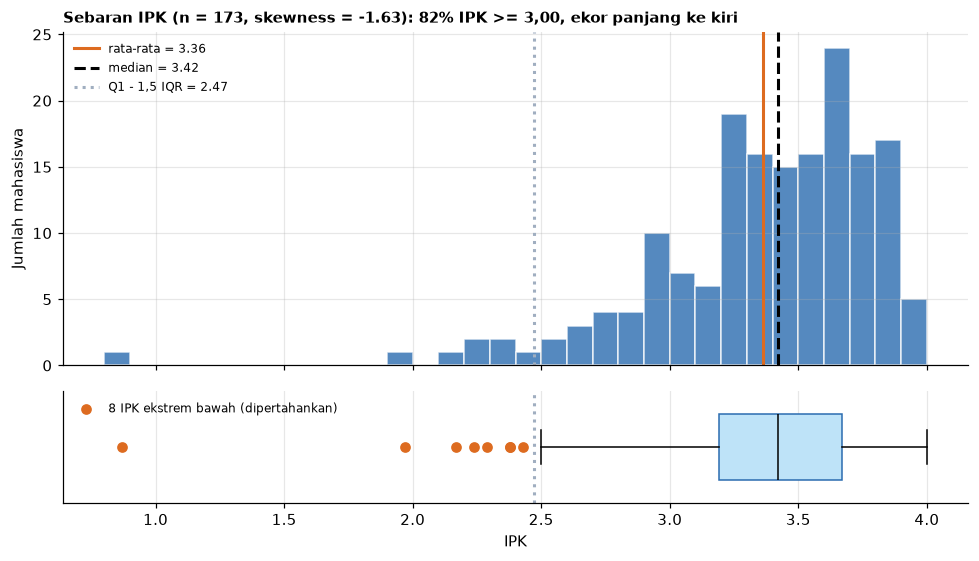

Disimpan: figures_and_outputs\B3_2_distribusi_ipk.png


In [17]:
ipk = df_reg[TARGET]
stat_ipk = pd.Series({
    "n": len(ipk), "rata-rata": ipk.mean(), "median": ipk.median(), "simpangan baku": ipk.std(),
    "min": ipk.min(), "Q1": q1, "Q3": q3, "max": ipk.max(), "skewness": stats.skew(ipk),
    "% IPK >= 3,00": (ipk >= 3.0).mean() * 100, "% IPK >= 3,50": (ipk >= 3.5).mean() * 100,
    "jumlah ekstrem bawah": len(ekstrem),
}).round(2).to_frame("IPK")
display(stat_ipk.T)
simpan_tabel(stat_ipk, "B3_2_statistik_ipk")

# boxplot horizontal; parameter berbeda antar versi matplotlib
ARAH_HORIZONTAL = ({"orientation": "horizontal"} if tuple(map(int, matplotlib.__version__.split(".")[:2])) >= (3, 10)
                   else {"vert": False})

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(9, 5.2), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax1.hist(ipk, bins=np.arange(0.8, 4.05, 0.1), color=BIRU, alpha=0.8, edgecolor="white")
ax1.axvline(ipk.mean(), color=ORANYE, lw=2, label=f"rata-rata = {ipk.mean():.2f}")
ax1.axvline(ipk.median(), color="black", lw=2, ls="--", label=f"median = {ipk.median():.2f}")
ax1.axvline(batas_bawah, color=ABU, lw=2, ls=":", label=f"Q1 - 1,5 IQR = {batas_bawah:.2f}")
ax1.set_ylabel("Jumlah mahasiswa")
ax1.set_title(f"Sebaran IPK (n = {len(ipk)}, skewness = {stats.skew(ipk):.2f}): {(ipk >= 3).mean() * 100:.0f}% IPK >= 3,00, "
              f"ekor panjang ke kiri",
              loc="left", fontsize=10, fontweight="bold")
ax1.legend(frameon=False, fontsize=8, loc="upper left")

ax2.boxplot(ipk, **ARAH_HORIZONTAL, widths=0.6, showfliers=False, patch_artist=True,
            boxprops=dict(facecolor="#bee3f8", color=BIRU), medianprops=dict(color="black"))
ax2.scatter(ekstrem[TARGET], np.ones(len(ekstrem)), color=ORANYE, zorder=3, label=f"{len(ekstrem)} IPK ekstrem bawah (dipertahankan)")
ax2.axvline(batas_bawah, color=ABU, lw=2, ls=":")
ax2.set_yticks([])
ax2.set_xlabel("IPK")
ax2.legend(frameon=False, fontsize=8, loc="upper left")
fig.tight_layout()
simpan_fig(fig, "B3_2_distribusi_ipk")

**Interpretasi B3.2**
- **Yang terlihat:** sebagian besar mahasiswa ber-IPK tinggi: 82% punya IPK ≥ 3,00 dan hampir separuh (46%) ≥ 3,50. Median (3,42) lebih besar dari rata-rata (3,36), karena rata-rata "tertarik" ke bawah oleh sedikit IPK rendah. Skewness −1,63 berarti sebarannya **menceng kiri**: menumpuk di nilai tinggi dengan ekor panjang ke arah nilai rendah. Ada 8 IPK di bawah 2,47, dan yang paling ekstrem (0,87) jauh terpisah dari yang lain.
- **Artinya:** IPK rendah adalah kasus langka di data ini. Model yang belajar dari data seperti ini cenderung menebak di sekitar 3,3–3,4, sehingga untuk mahasiswa ber-IPK rendah tebakannya akan terlalu tinggi.
- **Dampak ke modeling:**
  - Error terbesar diperkirakan ada di IPK rendah. Ini akan dicek di B6 dengan MAE per kelompok IPK.
  - **MAE** dipakai sebagai metrik utama karena paling mudah dibaca ("rata-rata tebakan meleset berapa poin IPK"). **RMSE** diperkirakan lebih besar dari MAE karena RMSE menghukum tebakan yang meleset jauh, dan tebakan seperti itu datang dari IPK rendah.
  - Model baru dianggap berguna kalau error-nya **lebih kecil daripada sekadar menebak rata-rata IPK** (baseline di B5).
  - IPK **tidak ditransformasi** (misalnya log), supaya prediksi langsung berada di skala IPK asli 0–4 seperti yang diminta untuk Streamlit.

## B3.3 Ringkasan fitur: pola pilihan VARK
Pertanyaan: **opsi mana yang sering dan jarang dipilih, dan berapa banyak opsi yang dipilih tiap orang?** Fitur yang hampir selalu 0 atau hampir selalu 1 membawa sedikit informasi untuk model.

,rata-rata % dipilih,skenario terendah,skenario tertinggi
Visual,48.2,Q03 (25%),Q14 (68%)
Aural,50.8,Q03 (33%),Q12 (73%)
Read/Write,45.1,Q04 (35%),Q03 (65%)
Kinesthetic,50.4,Q06 (27%),Q03 (68%)


Jumlah opsi dipilih per responden (dari 64): min 16, median 31, max 64; tepat 1 opsi per skenario (= 16): 18 orang
Opsi paling jarang : VARK_Q03_V (25%) | paling sering: VARK_Q12_A (73%)
Opsi dipilih < 10% atau > 90% responden: 0 dari 64
Disimpan: figures_and_outputs\B3_3_persen_opsi_dipilih.csv


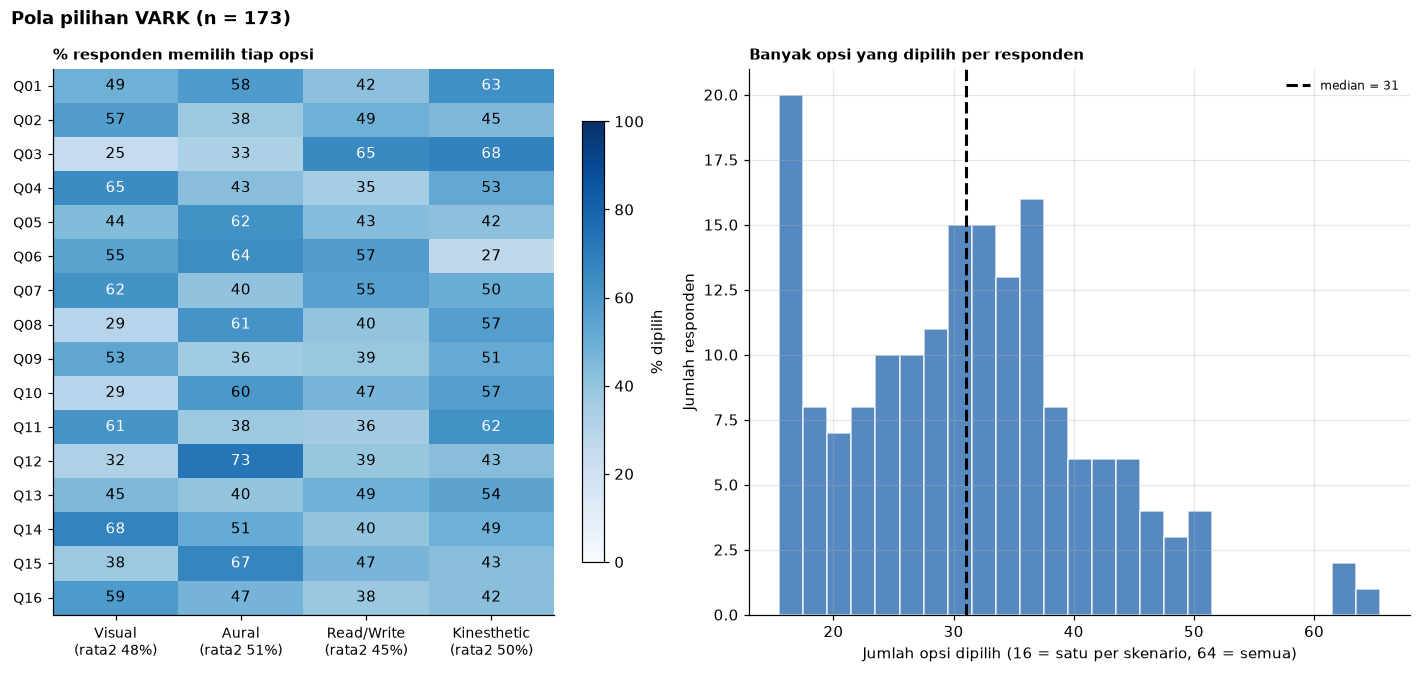

Disimpan: figures_and_outputs\B3_3_pola_fitur_vark.png


In [18]:
NAMA_MOD = {"V": "Visual", "A": "Aural", "R": "Read/Write", "K": "Kinesthetic"}
persen = df_reg[FEATURE_COLS].mean() * 100                       # % responden memilih tiap opsi
grid = pd.DataFrame([[persen[f"VARK_Q{q:02d}_{m}"] for m in MODALITAS] for q in range(1, 17)],
                    index=[f"Q{q:02d}" for q in range(1, 17)], columns=[NAMA_MOD[m] for m in MODALITAS])

ringkas_mod = pd.DataFrame({
    "rata-rata % dipilih": grid.mean(),
    "skenario terendah": [f"{grid[c].idxmin()} ({grid[c].min():.0f}%)" for c in grid],
    "skenario tertinggi": [f"{grid[c].idxmax()} ({grid[c].max():.0f}%)" for c in grid],
}).round(1)
display(ringkas_mod)

jumlah_opsi = df_reg[FEATURE_COLS].sum(axis=1)                    # hanya untuk EDA, bukan fitur
print(f"Jumlah opsi dipilih per responden (dari 64): min {jumlah_opsi.min()}, median {jumlah_opsi.median():.0f}, "
      f"max {jumlah_opsi.max()}; tepat 1 opsi per skenario (= 16): {(jumlah_opsi == 16).sum()} orang")
print(f"Opsi paling jarang : {persen.idxmin()} ({persen.min():.0f}%) | paling sering: {persen.idxmax()} ({persen.max():.0f}%)")
print(f"Opsi dipilih < 10% atau > 90% responden: {int(((persen < 10) | (persen > 90)).sum())} dari 64")
simpan_tabel(grid.round(1), "B3_3_persen_opsi_dipilih")

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.2), gridspec_kw={"width_ratios": [1, 1.2]})
im = ax1.imshow(grid.values, cmap="Blues", vmin=0, vmax=100, aspect="auto")
for i in range(grid.shape[0]):
    for j in range(grid.shape[1]):
        v = grid.values[i, j]
        ax1.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=10, color="white" if v > 60 else "black")
ax1.set_xticks(range(4), [f"{c}\n(rata2 {grid[c].mean():.0f}%)" for c in grid.columns], fontsize=9)
ax1.set_yticks(range(16), grid.index, fontsize=9)
ax1.grid(False)
ax1.set_title("% responden memilih tiap opsi", loc="left", fontsize=10, fontweight="bold")
fig.colorbar(im, ax=ax1, fraction=0.04, label="% dipilih")

ax2.hist(jumlah_opsi, bins=np.arange(15.5, 66, 2), color=BIRU, alpha=0.8, edgecolor="white")
ax2.axvline(jumlah_opsi.median(), color="black", ls="--", lw=2, label=f"median = {jumlah_opsi.median():.0f}")
ax2.set_xlabel("Jumlah opsi dipilih (16 = satu per skenario, 64 = semua)")
ax2.set_ylabel("Jumlah responden")
ax2.set_title("Banyak opsi yang dipilih per responden", loc="left", fontsize=10, fontweight="bold")
ax2.legend(frameon=False, fontsize=8)
fig.suptitle(f"Pola pilihan VARK (n = {len(df_reg)})", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "B3_3_pola_fitur_vark")

**Interpretasi B3.3**

**Grafik kiri (heatmap): opsi apa yang dipilih?**
Angka di setiap kotak = persentase dari 173 responden yang mencentang opsi itu. Contoh: baris Q03, kolom Kinesthetic = 68, artinya 68% responden memilih "berlatih soal/mencoba contoh" ketika mengingat materi menjelang ujian. Karena satu skenario boleh dijawab lebih dari satu opsi, jumlah satu baris bisa lebih dari 100%.
- Setiap opsi dipilih oleh **25%–73%** responden. Tidak ada opsi yang hampir tidak pernah atau hampir selalu dipilih (0 opsi di bawah 10% atau di atas 90%).
- Rata-rata per modalitas mirip (Read/Write 45%, Visual 48%, Kinesthetic 50%, Aural 51%), jadi **tidak ada modalitas yang mendominasi**. Pilihan lebih bergantung pada **situasinya**: Q03 (mengingat materi menjelang ujian) didominasi Kinesthetic 68% dan Read/Write 65%, tetapi Visual hanya 25%; Q12 (memastikan benar-benar paham) didominasi Aural 73%.

**Grafik kanan (histogram): berapa banyak opsi yang dipilih tiap orang?**
Untuk setiap responden dihitung total opsi yang dicentang dari 16 skenario. Nilai **16** berarti selalu memilih 1 opsi per skenario, nilai **64** berarti selalu memilih keempat opsi. Tinggi batang = jumlah orang dengan total tersebut.
- Kebanyakan orang memilih **sekitar 2 opsi per skenario** (median 31; 31 ÷ 16 ≈ 1,9).
- Batang paling kiri tinggi: ada kelompok "pemilih tegas", yaitu **18 orang** yang selalu memilih tepat 1 opsi.
- Di ujung kanan ada **3 orang** yang memilih ≥ 60 opsi (ID 55, 125, 132). Ketiganya juga straightliner di skala 1–5, jadi kemungkinan mengisi tanpa banyak membedakan. Mereka tetap dipertahankan (alasan di B2.5).

**Artinya:**
- Setiap fitur punya variasi yang cukup, jadi tidak ada fitur yang "kosong informasi".
- Banyaknya angka 1 di X tidak hanya mencerminkan preferensi belajar, tetapi juga **gaya mengisi survei**: ada yang hemat memilih, ada yang memilih hampir semua. Ini salah satu alasan fitur VARK sulit dipakai untuk menebak IPK.

**Dampak ke modeling:** seluruh 64 fitur dipakai sesuai panduan. Semua fitur sudah berskala sama (0/1), jadi Random Forest tidak memerlukan scaling. Scaling di pipeline Linear Regression hanya agar besar koefisiennya bisa dibandingkan.

## B3.4 Hubungan fitur dengan IPK
Pertanyaan: **apakah memilih opsi tertentu berkaitan dengan IPK yang lebih tinggi atau lebih rendah?**

Metode: korelasi **Spearman** antara setiap indikator (0/1) dan IPK. Spearman dipakai karena IPK menceng kiri dan punya nilai ekstrem. Untuk fitur biner, Spearman setara dengan korelasi point-biserial yang dihitung pada *peringkat* IPK (berkaitan dengan uji Mann–Whitney), sehingga tidak didominasi beberapa IPK sangat rendah. Karena ada 64 uji sekaligus, p-value dikoreksi dengan **FDR (Benjamini–Hochberg)**, seperti di UTS. Tanpa koreksi, sekitar 3 dari 64 uji diperkirakan "signifikan" hanya karena kebetulan.

**Penting:** hasil bagian ini hanya untuk memahami data. Fitur **tidak** dipilih atau dibuang berdasarkan korelasi ini.

|rho| maksimum : 0.20 (VARK_Q01_A)
p < 0,05 (tanpa koreksi): 5 dari 64 | diharapkan karena kebetulan: 3.2
q < 0,05 (setelah FDR)  : 0 dari 64


,rho,p,q_FDR,IPK median dipilih,IPK median tidak dipilih
fitur,,,,,
VARK_Q01_A,0.198,0.009,0.343,3.520,3.300
VARK_Q14_A,0.194,0.011,0.343,3.520,3.400
VARK_Q16_A,0.178,0.019,0.414,3.540,3.360
VARK_Q04_A,0.161,0.035,0.461,3.515,3.340
VARK_Q09_R,-0.154,0.043,0.461,3.360,3.475


Disimpan: figures_and_outputs\B3_4_korelasi_fitur_ipk.csv


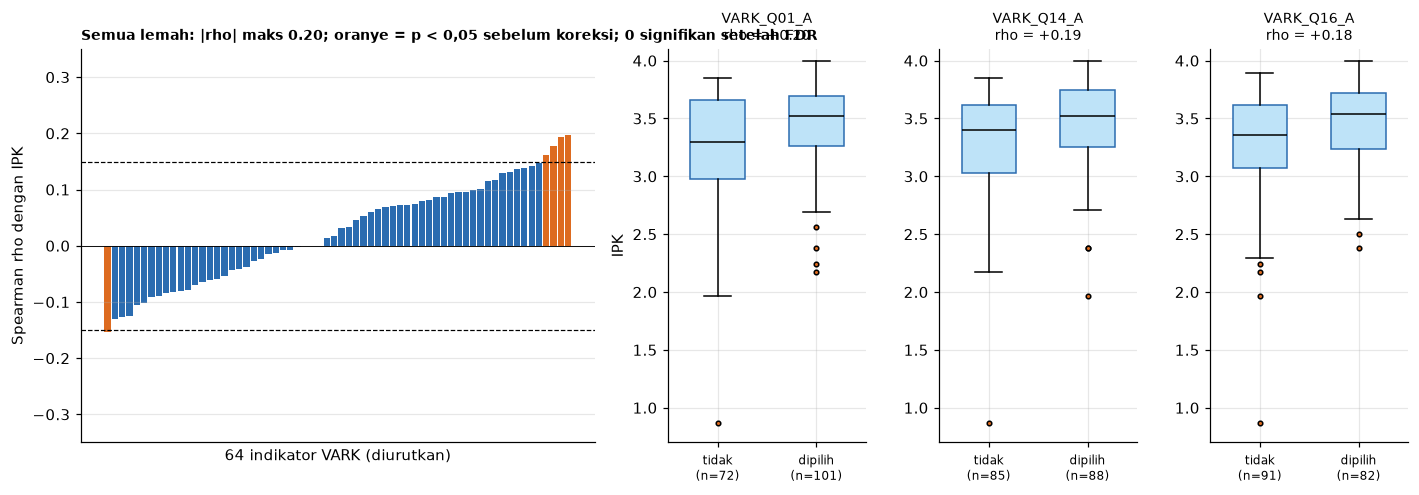

Disimpan: figures_and_outputs\B3_4_hubungan_fitur_ipk.png


In [19]:
kor = pd.DataFrame([(c, *stats.spearmanr(df_reg[c], df_reg[TARGET])) for c in FEATURE_COLS],
                   columns=["fitur", "rho", "p"]).set_index("fitur")
kor["q_FDR"] = stats.false_discovery_control(kor["p"])
kor["IPK median dipilih"] = [df_reg.loc[df_reg[c] == 1, TARGET].median() for c in kor.index]
kor["IPK median tidak dipilih"] = [df_reg.loc[df_reg[c] == 0, TARGET].median() for c in kor.index]
kor = kor.reindex(kor["rho"].abs().sort_values(ascending=False).index)

print(f"|rho| maksimum : {kor['rho'].abs().max():.2f} ({kor.index[0]})")
print(f"p < 0,05 (tanpa koreksi): {int((kor['p'] < 0.05).sum())} dari 64 | diharapkan karena kebetulan: {0.05 * 64:.1f}")
print(f"q < 0,05 (setelah FDR)  : {int((kor['q_FDR'] < 0.05).sum())} dari 64")
display(kor.head(5).round(3))
simpan_tabel(kor.round(4), "B3_4_korelasi_fitur_ipk")

top3 = kor.index[:3].tolist()
batas_p05 = 1.96 / np.sqrt(len(df_reg) - 1)          # perkiraan |rho| untuk p = 0,05

fig = plt.figure(figsize=(13, 4.6))
gs = fig.add_gridspec(1, 4, width_ratios=[2.6, 1, 1, 1])
ax = fig.add_subplot(gs[0])
urut = kor.sort_values("rho")
ax.bar(range(64), urut["rho"], color=[ORANYE if p < 0.05 else BIRU for p in urut["p"]], width=0.85)
for y in (batas_p05, -batas_p05):
    ax.axhline(y, color="black", ls="--", lw=0.8)
ax.axhline(0, color="black", lw=0.6)
ax.set_xticks([])
ax.set_xlabel("64 indikator VARK (diurutkan)")
ax.set_ylabel("Spearman rho dengan IPK")
ax.set_ylim(-0.35, 0.35)
ax.set_title(f"Semua lemah: |rho| maks {kor['rho'].abs().max():.2f}; oranye = p < 0,05 sebelum koreksi; "
             f"{int((kor['q_FDR'] < 0.05).sum())} signifikan setelah FDR", loc="left", fontsize=9, fontweight="bold")

for k, c in enumerate(top3):
    axb = fig.add_subplot(gs[k + 1])
    data = [df_reg.loc[df_reg[c] == 0, TARGET], df_reg.loc[df_reg[c] == 1, TARGET]]
    axb.boxplot(data, widths=0.55, patch_artist=True, boxprops=dict(facecolor="#bee3f8", color=BIRU),
                medianprops=dict(color="black"), flierprops=dict(marker="o", markersize=3, markerfacecolor=ORANYE))
    axb.set_xticks([1, 2], [f"tidak\n(n={len(data[0])})", f"dipilih\n(n={len(data[1])})"], fontsize=8)
    axb.set_ylim(0.7, 4.1)
    axb.set_title(f"{c}\nrho = {kor.loc[c, 'rho']:+.2f}", fontsize=9)
    if k == 0:
        axb.set_ylabel("IPK")
fig.tight_layout()
simpan_fig(fig, "B3_4_hubungan_fitur_ipk")

**Interpretasi B3.4**
- **Yang terlihat:**
  - **Semua hubungan lemah.** Korelasi terbesar hanya 0,20 (`VARK_Q01_A`). Sebagai gambaran, ρ = 0,20 berarti fitur itu hanya berkaitan dengan sekitar 4% (0,20²) variasi peringkat IPK.
  - Ada 5 dari 64 fitur dengan p < 0,05, padahal **karena kebetulan saja** sudah diharapkan sekitar 3 (5% × 64). Setelah koreksi FDR, **0 yang signifikan**. Jadi "sinyal" ini tidak bisa dibedakan dari kebetulan.
  - Ada pola kecil yang menarik: 4 dari 5 fitur teratas adalah opsi **Aural** (Q01, Q14, Q16, Q04). Mahasiswa yang memilih opsi "mendengar/berdiskusi" punya median IPK sekitar 0,1–0,2 poin lebih tinggi. Namun di boxplot, kotak (50% data tengah) kedua kelompok **sangat tumpang tindih**, jadi bedanya kecil dibanding sebaran IPK.
- **Artinya:** memilih opsi VARK tertentu hampir tidak memberi petunjuk tentang IPK seseorang. Pola Aural pun hanya kecenderungan lemah dan **bukan sebab-akibat**.
- **Dampak ke modeling:**
  - R² model diperkirakan **mendekati 0, bahkan bisa negatif**. Itu hasil yang sah selama prosesnya benar, dan rubrik menilai proses serta interpretasi, bukan besar R².
  - **Baseline** (menebak rata-rata) wajib ada sebagai pembanding di B5.
  - Fitur tidak dipilih berdasarkan korelasi ini (menghindari leakage); seluruh 64 fitur tetap dipakai.

## B3.5 Korelasi antar-fitur (cek multikolinearitas)
Pertanyaan: **apakah ke-64 fitur saling tumpang-tindih?** Kalau banyak fitur saling berkorelasi kuat (multikolinearitas), koefisien Linear Regression menjadi tidak stabil. Ukuran yang dipakai:
- korelasi antar-fitur (heatmap diurutkan per modalitas), dan
- **VIF** (*Variance Inflation Factor*): seberapa besar satu fitur bisa ditebak dari 63 fitur lainnya. Patokan umum: VIF > 5 perlu diwaspadai, > 10 bermasalah.

Bagian ini tidak melibatkan IPK sama sekali, sehingga aman dihitung sebelum split. Hasilnya hanya deskriptif.

,nilai
jumlah pasangan fitur,2016.00
rata-rata |r|,0.12
|r| maksimum,0.51
"pasangan dengan |r| > 0,5",2.00
"r rata-rata: modalitas sama, skenario beda",0.24
r rata-rata: opsi dalam skenario yang sama,-0.07
VIF median,2.48
VIF maksimum,3.52
fitur dengan VIF > 5,0.00


Disimpan: figures_and_outputs\B3_5_korelasi_antar_fitur.csv
Rata-rata korelasi per blok modalitas:


,Visual,Aural,Read/Write,Kinesthetic
Visual,0.29,0.02,0.04,0.06
Aural,0.02,0.19,0.08,-0.00
Read/Write,0.04,0.08,0.21,0.06
Kinesthetic,0.06,-0.00,0.06,0.29


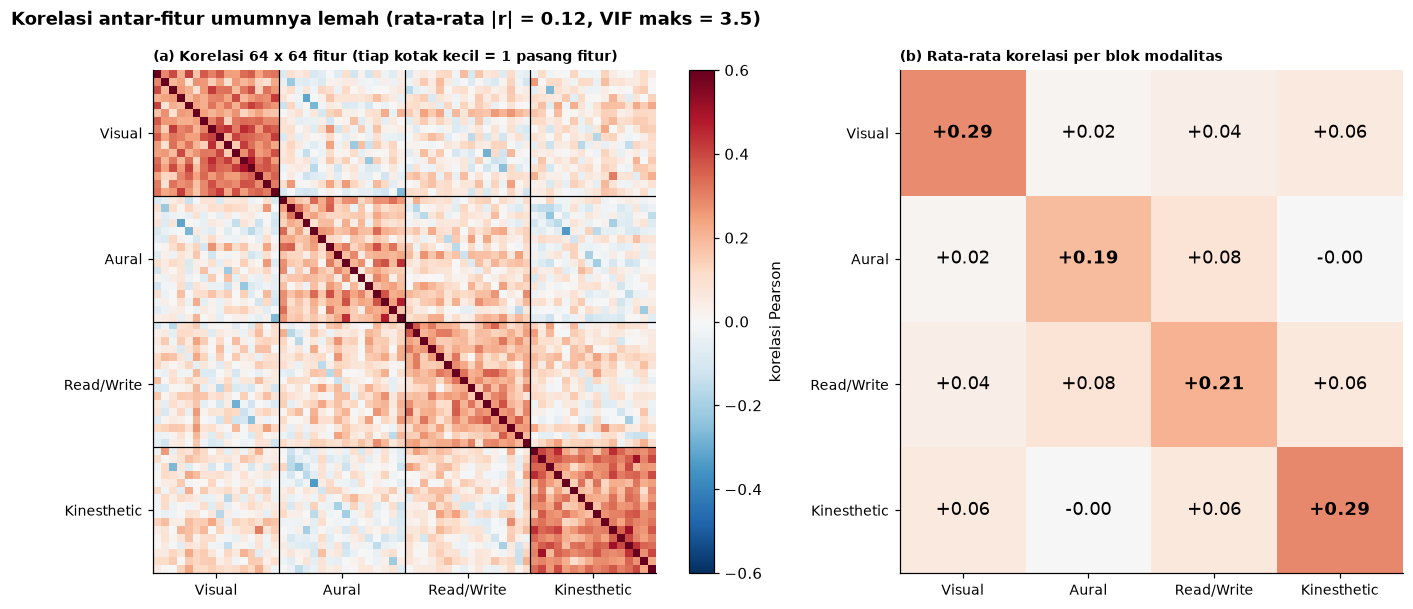

Disimpan: figures_and_outputs\B3_5_korelasi_antar_fitur.png


In [20]:
URUT_MOD = [f"VARK_Q{q:02d}_{m}" for m in MODALITAS for q in range(1, 17)]   # dikelompokkan per modalitas
korX = df_reg[URUT_MOD].corr()
iu = np.triu_indices(64, k=1)
nilai_r = korX.values[iu]
mod_i = np.array([c[-1] for c in URUT_MOD])
skn_i = np.array([c[6:8] for c in URUT_MOD])
sama_mod = (mod_i[iu[0]] == mod_i[iu[1]]) & (skn_i[iu[0]] != skn_i[iu[1]])
sama_skn = skn_i[iu[0]] == skn_i[iu[1]]

vif = pd.Series(np.diag(np.linalg.inv(korX.values)), index=URUT_MOD)   # VIF_j = diagonal invers matriks korelasi

ringkas_kor = pd.Series({
    "jumlah pasangan fitur": len(nilai_r),
    "rata-rata |r|": np.abs(nilai_r).mean(),
    "|r| maksimum": np.abs(nilai_r).max(),
    "pasangan dengan |r| > 0,5": int((np.abs(nilai_r) > 0.5).sum()),
    "r rata-rata: modalitas sama, skenario beda": nilai_r[sama_mod].mean(),
    "r rata-rata: opsi dalam skenario yang sama": nilai_r[sama_skn].mean(),
    "VIF median": vif.median(),
    "VIF maksimum": vif.max(),
    "fitur dengan VIF > 5": int((vif > 5).sum()),
}).round(2).to_frame("nilai")
display(ringkas_kor)
simpan_tabel(ringkas_kor, "B3_5_korelasi_antar_fitur")

# Ringkasan per blok modalitas: rata-rata korelasi antar-fitur (diagonal: modalitas sama, skenario berbeda)
nama4 = [NAMA_MOD[m] for m in MODALITAS]
blok = pd.DataFrame(index=nama4, columns=nama4, dtype=float)
for a in range(4):
    for b in range(4):
        sub = korX.values[16 * a:16 * (a + 1), 16 * b:16 * (b + 1)]
        blok.iloc[a, b] = sub[~np.eye(16, dtype=bool)].mean() if a == b else sub.mean()
print("Rata-rata korelasi per blok modalitas:")
display(blok.round(2))

fig, (ax, ax2) = plt.subplots(1, 2, figsize=(13, 5.6), gridspec_kw={"width_ratios": [1.25, 1]})
im = ax.imshow(korX.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
for b in range(1, 4):
    ax.axhline(b * 16 - 0.5, color="black", lw=0.8)
    ax.axvline(b * 16 - 0.5, color="black", lw=0.8)
pos = [7.5 + 16 * k for k in range(4)]
ax.set_xticks(pos, nama4, fontsize=9)
ax.set_yticks(pos, nama4, fontsize=9)
ax.grid(False)
fig.colorbar(im, ax=ax, fraction=0.046, label="korelasi Pearson")
ax.set_title("(a) Korelasi 64 x 64 fitur (tiap kotak kecil = 1 pasang fitur)", loc="left", fontsize=9, fontweight="bold")

im2 = ax2.imshow(blok.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6)
for a in range(4):
    for b in range(4):
        ax2.text(b, a, f"{blok.values[a, b]:+.2f}", ha="center", va="center", fontsize=12,
                 fontweight="bold" if a == b else "normal")
ax2.set_xticks(range(4), nama4, fontsize=9)
ax2.set_yticks(range(4), nama4, fontsize=9)
ax2.grid(False)
ax2.set_title("(b) Rata-rata korelasi per blok modalitas", loc="left", fontsize=9, fontweight="bold")
fig.suptitle(f"Korelasi antar-fitur umumnya lemah (rata-rata |r| = {np.abs(nilai_r).mean():.2f}, VIF maks = {vif.max():.1f})",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
simpan_fig(fig, "B3_5_korelasi_antar_fitur")

**Interpretasi B3.5**

**Cara membaca grafik:**
- **Grafik (a)** berisi 64 × 64 kotak kecil; tiap kotak adalah korelasi satu pasang fitur. Merah = sering dipilih bersamaan, biru = jarang dipilih bersamaan, putih = tidak berhubungan. Fitur diurutkan per modalitas (16 skenario Visual, lalu Aural, dst.), sehingga terbentuk 4 kotak besar. Grafik ini terlalu padat untuk diberi angka.
- **Grafik (b)** meringkas grafik (a) menjadi 4 × 4: setiap angka adalah **rata-rata korelasi** di satu kotak besar.

**Yang terlihat:**
- Fitur umumnya **tidak saling tumpang tindih**: rata-rata |r| = 0,12, maksimum 0,51, dan hanya 2 dari 2.016 pasangan yang |r| > 0,5. **VIF maksimum 3,5**, masih di bawah batas waspada 5.
- **Diagonal grafik (b)** bernilai +0,19 sampai +0,29: orang yang memilih opsi Visual di satu skenario cenderung memilih Visual juga di skenario lain, begitu pula modalitas lain. Ini wajar dan menunjukkan jawaban responden cukup konsisten.
- **Di luar diagonal** nilainya hampir 0 (−0,00 sampai +0,08): memilih satu modalitas tidak membuat orang lebih atau kurang memilih modalitas lain.

**Artinya:** multikolinearitas **ringan**, jadi bukan masalah utama untuk Linear Regression.

**Dampak ke modeling:** risiko overfit Linear Regression lebih disebabkan **jumlah fitur yang banyak dibanding jumlah data**: 64 fitur (+1 intercept) untuk sekitar 138 baris training, atau hampir 1 parameter untuk setiap 2 data. Dengan perbandingan seperti itu, model bisa "menghafal" data training tetapi gagal di data baru. Dugaan ini akan dibuktikan di B5 dengan membandingkan error training dan error cross-validation.

## B3.6 Kesimpulan EDA: apa yang kami pelajari dan apa artinya untuk modeling

**Ringkasnya:** datanya sudah bersih dan siap dipakai (173 mahasiswa, 64 fitur, tanpa nilai kosong). Namun, jawaban VARK hampir tidak berhubungan dengan IPK. Jadi kami **tidak berharap model bisa menebak IPK dengan akurat**. Tujuan modeling adalah menguji hal itu secara adil: apakah Linear Regression dan Random Forest bisa lebih baik daripada tebakan paling sederhana, yaitu menebak rata-rata IPK.

| # | Yang kami temukan | Jadi, di tahap modeling kami... |
|---|---|---|
| 1 | 19 mahasiswa tanpa IPK sudah dikeluarkan, dan tidak ada fitur yang kosong (B3.1) | memakai 173 baris dan tidak perlu mengisi data kosong (imputasi) |
| 2 | Kebanyakan IPK tinggi (82% ≥ 3,00); IPK rendah hanya sedikit, termasuk 8 nilai ekstrem (B3.2) | memakai **MAE** sebagai ukuran utama karena mudah dibaca ("rata-rata tebakan meleset berapa poin IPK"), ditambah RMSE dan R². Kami juga mengecek apakah error terbesar ada di IPK rendah (B6). Skala IPK tidak diubah |
| 3 | Semua 64 opsi cukup bervariasi dan nilainya 0/1; banyaknya opsi yang dipilih juga dipengaruhi gaya mengisi survei (B3.3) | memakai semua 64 fitur; scaling hanya untuk Linear Regression |
| 4 | Tidak ada opsi yang berhubungan nyata dengan IPK: korelasi paling besar 0,20 dan 0 yang signifikan setelah koreksi (B3.4) | membandingkan setiap model dengan **baseline "tebak rata-rata"**. R² sekitar 0 atau negatif kami anggap hasil yang wajar, bukan kesalahan |
| 5 | Fitur tidak saling tumpang tindih (VIF maks 3,5), tetapi jumlahnya banyak (64) dibanding data training (±138) (B3.5) | mewaspadai Linear Regression yang "menghafal" data training, dan membuktikannya dengan membandingkan error training vs cross-validation (B5) |
| 6 | Sinyalnya lemah dan datanya sedikit | membatasi Random Forest supaya tidak menghafal: setiap daun pohon minimal berisi beberapa data (`min_samples_leaf`), dipilih lewat GridSearchCV |
| 7 | Data test hanya ±35 baris, sehingga angkanya mudah berubah | memilih model dari cross-validation di data training; data test hanya dipakai **sekali** di akhir (B6) |

### Checkpoint: data siap untuk modeling
Sel ini hanya memastikan bahan untuk B4 sudah lengkap: **X** (173 × 64), **y** (173 IPK), tanpa nilai kosong, dan `ID` disimpan terpisah (bukan fitur) untuk menelusuri error di B6. Pembagian train/test baru dilakukan di B4.

In [21]:
X = df_reg[FEATURE_COLS]
y = df_reg[TARGET]
id_reg = df_reg["ID"]          # hanya untuk menelusuri error di B6, bukan fitur

assert X.shape == (173, 64) and y.shape == (173,)
assert not X.isna().any().any() and not y.isna().any()
assert list(X.columns) == FEATURE_COLS and "ID" not in X.columns
print(f"X: {X.shape} | y: {y.shape} | IPK {y.min():.2f}-{y.max():.2f} | ID unik: {id_reg.is_unique}")
print("Data siap masuk B4 (split & pipeline).")

X: (173, 64) | y: (173,) | IPK 0.87-4.00 | ID unik: True
Data siap masuk B4 (split & pipeline).
